# BI10 Round 02 — Challenge 1 | Final Delivery & Validation Pack

**Purpose:** Publish auditable customer-level FHS results, selected scoring parameters, historical approval diagnostics and business-ready explanations. **No rescoring or refitting.** All inputs are read-only; only `C1_CHALLENGE1_FINAL/` is updated. This notebook uses the SAME calibrated run (CSV + config + validation tables), so the audit trail cannot mix different versions.

**Interpretation:** FHS is a proxy-based financial health indicator, **not** a calibrated PD or a prospective approval prediction. Approval validation is retrospective and descriptive. `FULL` means two observed scoring pillars, **not** verified bank-level data quality.

## 01 · Configuration and sources

In [1]:
from pathlib import Path
import json, shutil, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = None                 # Example: r'C:\Users\...\BI10_ROUND02_DATASET'
CALIBRATED_RUN_DIR = None          # Exact C1_FINAL_VALIDATION_OUTPUT/run_* path if needed
EXPECTED_CUSTOMERS = 1_000_528   # Fail fast if another population is read
MIN_APPROVAL_CASES = 100         # For display only, not deletion
REQUIRED_YEAR_MIN = 2009
FINAL_FOLDER_NAME = 'C1_CHALLENGE1_FINAL'
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':180, 'axes.spines.top':False, 'axes.spines.right':False})

## 02 · Locate a complete calibrated run (never mix run folders)

In [2]:
roots = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path.cwd().resolve().parent.parent]
if PROJECT_DIR: roots.insert(0,Path(PROJECT_DIR).expanduser().resolve())
if CALIBRATED_RUN_DIR:
    run = Path(CALIBRATED_RUN_DIR).expanduser().resolve()
else:
    candidates = {p.resolve() for root in roots for parent in (root,root/'BI10_ROUND02_DATASET')
                  for p in parent.glob('C1_FINAL_VALIDATION_OUTPUT/run_*') if p.is_dir()}
    complete = [p for p in candidates if (p/'selected_scoring_config.json').is_file()
                and (p/'tables/10_customer_fhs_final.csv').is_file()]
    if not complete: raise FileNotFoundError('Cannot locate calibrated run. Set CALIBRATED_RUN_DIR explicitly.')
    run = max(complete,key=lambda p:(p/'selected_scoring_config.json').stat().st_mtime)
source_csv = run/'tables/10_customer_fhs_final.csv'
source_cfg = run/'selected_scoring_config.json'
project = run.parent.parent
out = project/FINAL_FOLDER_NAME
figdir = out/'figures'
out.mkdir(exist_ok=True); figdir.mkdir(exist_ok=True)
print('CALIBRATED RUN:',run,'\nFIXED FINAL OUTPUT:',out)

CALIBRATED RUN: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_FINAL_VALIDATION_OUTPUT\run_20261018_122943_11af97 
FIXED FINAL OUTPUT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_CHALLENGE1_FINAL


## 03 · Load parameters; preserve selected methodology

In [3]:
config = json.loads(source_cfg.read_text(encoding='utf-8'))
for key in ('scoring_version','capacity_weight','a1_weight','prior_k','p0_due_case_proxy',
            'odsr_good','odsr_stress','residual_p10','residual_p90','written_off_cap'):
    if key not in config: raise ValueError(f'Missing selected configuration: {key}')
wc = float(config['capacity_weight']); wa = float(config['a1_weight']); cap = float(config['written_off_cap'])
assert 0<=wc<=1 and 0<=wa<=1 and 0<=cap<=100
print('Version:',config['scoring_version'],'| Capacity weight:',wc,'| A1 weight:',wa,
      '| Payment k:',round(config['prior_k'],5),'| Written-off cap:',cap)

Version: BI10_FHS_V2.1_CALIBRATED | Capacity weight: 0.5 | A1 weight: 0.8 | Payment k: 6.35079 | Written-off cap: 50.0


## 04 · Read final score — one row per customer

In [4]:
needed = ['SKP_CLIENT','CAPACITY_SCORE','PAYMENT_SCORE','CAPACITY_USED','PAYMENT_USED',
 'FINANCIAL_HEALTH_SCORE','SCORE_EVIDENCE_FLAG','FHS_BEFORE_WO_CAP','WO_CAP_IMPACT',
 'WRITTEN_OFF_OBSERVED','NO_ACTIVE_INTERNAL_DEBT','A1_SCORE','A2_SCORE','P1_SCORE',
 'ODSR_PROXY','RESIDUAL_INCOME_PROXY','CAPACITY_CONTRIBUTION','PAYMENT_CONTRIBUTION',
 'SCORING_VERSION','IMPUTATION_SOURCE','FINANCIAL_HEALTH_SEGMENT','DATA_WARNINGS']
header = pd.read_csv(source_csv,nrows=0).columns.tolist()
missing = set(needed)-set(header)
if missing: raise ValueError(f'Calibrated customer CSV is missing: {sorted(missing)}; rerun the corrected final calibration notebook.')
score = pd.read_csv(source_csv,dtype={'SKP_CLIENT':'string'},low_memory=False)
assert len(score)==EXPECTED_CUSTOMERS, f'Expected {EXPECTED_CUSTOMERS:,}; got {len(score):,}'
assert score.SKP_CLIENT.notna().all() and score.SKP_CLIENT.is_unique
assert (score.SCORING_VERSION==config['scoring_version']).all(), 'Run/config version mismatch'
print('CUSTOMERS:',f'{len(score):,}','| COLUMNS:',len(score.columns))

CUSTOMERS: 1,000,528 | COLUMNS: 34


## 05 · Financial integrity — recompute selected FHS from saved components

In [5]:
def read_bool(series):
    val = series.astype('string').str.strip().str.lower()
    invalid = val.notna()&(~val.isin(['true','false','1','0']))
    if invalid.any(): raise ValueError(f'Unknown boolean values: {val[invalid].unique()[:5]}')
    return val.isin(['true','1']).to_numpy(bool)

wo = read_bool(score.WRITTEN_OFF_OBSERVED)
no_active = read_bool(score.NO_ACTIVE_INTERNAL_DEBT)
C = score.CAPACITY_USED.to_numpy(float); P = score.PAYMENT_USED.to_numpy(float)
actual = score.FINANCIAL_HEALTH_SCORE.to_numpy(float)
pre = wc*C+(1-wc)*P
expected = np.where(wo,np.minimum(pre,cap),pre)
finite = np.isfinite(actual)
assert np.array_equal(finite,np.isfinite(expected)), 'Missing-score mismatch'
assert np.allclose(actual[finite],expected[finite],atol=3e-5,rtol=0), 'FHS formula mismatch'
assert np.all((actual[finite]>=0)&(actual[finite]<=100))
assert np.all(actual[wo&finite]<=cap+3e-5)
print('PASS: score formula, 0–100 and WO cap. SCORABLE:',f'{finite.sum():,}')

PASS: score formula, 0–100 and WO cap. SCORABLE: 762,665


## 06 · Evidence status and completeness checks

In [6]:
flags = score.SCORE_EVIDENCE_FLAG.fillna('UNKNOWN').to_numpy(str)
known = {'FULL','CAPACITY_IMPUTED','PAYMENT_IMPUTED','NO_EVIDENCE'}
assert set(flags).issubset(known), 'Unexpected evidence flag'
assert np.array_equal(finite,flags!='NO_EVIDENCE')
assert score.loc[flags=='CAPACITY_IMPUTED','CAPACITY_SCORE'].isna().all()
assert score.loc[flags=='PAYMENT_IMPUTED','PAYMENT_SCORE'].isna().all()
assert score.loc[flags=='FULL',['CAPACITY_SCORE','PAYMENT_SCORE']].notna().all().all()
coverage = score.groupby('SCORE_EVIDENCE_FLAG',sort=False).agg(
    CUSTOMERS=('SKP_CLIENT','size'),SCORED=('FINANCIAL_HEALTH_SCORE','count'),
    MEAN_FHS=('FINANCIAL_HEALTH_SCORE','mean'),MEDIAN_FHS=('FINANCIAL_HEALTH_SCORE','median'),
    STD_FHS=('FINANCIAL_HEALTH_SCORE','std')).reset_index()
coverage['PCT_CUSTOMERS'] = 100*coverage.CUSTOMERS/len(score)
display(coverage.round(3))

,SCORE_EVIDENCE_FLAG,CUSTOMERS,SCORED,MEAN_FHS,MEDIAN_FHS,STD_FHS,PCT_CUSTOMERS
0,FULL,471605,471605,67.830,70.300,10.811,47.136
1,CAPACITY_IMPUTED,171969,171969,71.200,71.877,5.616,17.188
2,PAYMENT_IMPUTED,119091,119091,66.459,69.107,9.467,11.903
3,NO_EVIDENCE,237863,0,NaN,NaN,NaN,23.774


## 07 · Join payment observation counts (evidence only; do not rescore)

In [7]:
mart_path = Path(config.get('source_mart',''))
if not mart_path.is_file():
    pool = sorted(project.glob('C1_STEP3_OUTPUT/run_*/tables/03_customer_feature_mart.csv'),
                  key=lambda p:p.stat().st_mtime, reverse=True)
    if not pool: raise FileNotFoundError('Step 3 Feature Mart missing; cannot audit payment evidence.')
    mart_path = pool[0]
mart_cols = pd.read_csv(mart_path,nrows=0).columns
extra = ['SKP_CLIENT','n_payment_observable_resolved_proxy','n_due_resolved_proxy','n_written_off_cases',
         'n_active_cases_with_annuity','n_active_cases_missing_annuity']
if set(extra)-set(mart_cols): raise ValueError('Missing payment evidence columns in mart')
small = pd.read_csv(mart_path,usecols=extra,dtype={'SKP_CLIENT':'string'})
assert small.SKP_CLIENT.is_unique
score = score.merge(small,on='SKP_CLIENT',validate='one_to_one',how='left',indicator=True)
assert (score._merge=='both').all(), 'Some customers missing in Feature Mart'
score.drop(columns=['_merge'],inplace=True)
print('MART matched:',f'{len(score):,}','|',mart_path)

MART matched: 1,000,528 | C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\tables\03_customer_feature_mart.csv


## 08 · Explainable score impacts (vs neutral 50; no invented causal claims)

In [8]:
N = len(score)
wa1 = wc*wa; wa2=wc*(1-wa); wp=(1-wc)
a1 = score.A1_SCORE.to_numpy(float); a2=score.A2_SCORE.to_numpy(float)
p1s = score.P1_SCORE.to_numpy(float)
impact_a1 = np.where(np.isfinite(a1),wa1*(a1-50),0.)
impact_a2 = np.where(np.isfinite(a2),wa2*(a2-50),0.)
impact_p1 = np.where(np.isfinite(p1s),wp*(p1s-50),0.)
impact_cap = score.WO_CAP_IMPACT.fillna(0).to_numpy(float)
imp_c = np.where(flags=='CAPACITY_IMPUTED',wc*(C-50),0.)
imp_p = np.where(flags=='PAYMENT_IMPUTED',wp*(P-50),0.)
recovered = 50+impact_a1+impact_a2+impact_p1+imp_c+imp_p+impact_cap
assert np.allclose(recovered[finite],actual[finite],atol=3e-5,rtol=0), 'Factor attribution failed'
for col,val in [('A1_SCORE_IMPACT',impact_a1),('A2_SCORE_IMPACT',impact_a2),
                ('P1_SCORE_IMPACT',impact_p1),('P3_CAP_IMPACT',impact_cap),
                ('IMPUTED_SCORE_IMPACT',imp_c+imp_p)]: score[col] = np.where(finite,val,np.nan)
print('PASS: 50 + observed impacts + imputed contribution + cap = final FHS')

PASS: 50 + observed impacts + imputed contribution + cap = final FHS


## 09 · Top positive/negative factors (observed only)

In [9]:
drivers = np.column_stack([impact_a1,impact_a2,impact_p1,impact_cap])
labels = np.array(['A1_DEBT_BURDEN_PROXY','A2_RESIDUAL_INCOME_PROXY',
                   'P1_PAYMENT_HISTORY_PROXY','P3_WRITTEN_OFF_CAP'])
pos_ix = np.argmax(drivers,axis=1); neg_ix = np.argmin(drivers,axis=1)
pos_v=drivers[np.arange(N),pos_ix];neg_v=drivers[np.arange(N),neg_ix]
positive=np.where(finite&(pos_v>1e-8),labels[pos_ix],'NONE')
negative=np.where(finite&(neg_v< -1e-8),labels[neg_ix],'NONE')
score['TOP_POSITIVE_FACTOR']=positive;score['TOP_NEGATIVE_FACTOR']=negative
score['TOP_POSITIVE_IMPACT_POINTS']=np.where(positive!='NONE',pos_v,np.nan)
score['TOP_NEGATIVE_IMPACT_POINTS']=np.where(negative!='NONE',neg_v,np.nan)
print('Top positive:\n',score.TOP_POSITIVE_FACTOR.value_counts().head(5).to_string())
print('Top negative:\n',score.TOP_NEGATIVE_FACTOR.value_counts().head(5).to_string())

Top positive:
 TOP_POSITIVE_FACTOR
A1_DEBT_BURDEN_PROXY        534768
NONE                        251006
P1_PAYMENT_HISTORY_PROXY    213333
A2_RESIDUAL_INCOME_PROXY      1421
Top negative:
 TOP_NEGATIVE_FACTOR
NONE                        597153
A2_RESIDUAL_INCOME_PROXY    332177
P1_PAYMENT_HISTORY_PROXY     36265
A1_DEBT_BURDEN_PROXY         29161
P3_WRITTEN_OFF_CAP            5772


## 10 · Data-supported business reason codes (separate facts from score mechanics)

In [10]:
n_pay=score.n_payment_observable_resolved_proxy.fillna(0).to_numpy(float)
n_due=score.n_due_resolved_proxy.fillna(0).to_numpy(float)
case_warn=score.n_active_cases_missing_annuity.fillna(0).to_numpy(float)>0
positive_flags = [((a1>=75)&np.isfinite(a1)&~no_active,'LOW_OBSERVED_DEBT_BURDEN'),
                  ((a2>=75)&np.isfinite(a2),'HIGH_RESIDUAL_INCOME_PROXY'),
                  ((n_pay>=3)&(n_due==0)&np.isfinite(p1s),'NO_DUE_IN_OBSERVED_CASES')]
negative_flags = [((a1<40)&np.isfinite(a1),'HIGH_OBSERVED_DEBT_BURDEN'),
                  ((a2<30)&np.isfinite(a2),'LOW_RESIDUAL_INCOME_PROXY'),
                  ((n_due>0)&np.isfinite(p1s),'DUE_FLAGS_RECORDED'),
                  (wo,'WRITTEN_OFF_HISTORY')]
def combine_reasons(rules):
    out = np.full(N,'',dtype=object)
    for mask,label in rules:
        out = np.char.add(out.astype(str),np.where(mask,label+';',''))
    return np.char.rstrip(out,';')
score['POSITIVE_EVIDENCE_CODES']=combine_reasons(positive_flags)
score['NEGATIVE_EVIDENCE_CODES']=combine_reasons(negative_flags)
score['DATA_ENRICHMENT_FLAG']=np.where(flags=='NO_EVIDENCE','NEED_FINANCIAL_EVIDENCE',
    np.where(flags!='FULL','IMPUTED_PILLAR_REVIEW',
    np.where(no_active,'NO_ACTIVE_INTERNAL_DEBT_REVIEW',
    np.where(case_warn,'INCOMPLETE_ACTIVE_ANNUITY_REVIEW','STANDARD_REVIEW'))))
print('Positive and negative evidence flags created; no new scores assigned.')

Positive and negative evidence flags created; no new scores assigned.


## 11 · Business segmentation overlay; severe event always has priority

In [11]:
band = np.select([actual<40,actual<60,actual<80,actual>=80],
    ['FINANCIAL_STRESS','WATCHLIST','MODERATE','STRONG'],default='INSUFFICIENT_EVIDENCE')
assert np.array_equal(band,score.FINANCIAL_HEALTH_SEGMENT.fillna('INSUFFICIENT_EVIDENCE').to_numpy(str)) or        np.array_equal(np.where(finite,band,'NO_EVIDENCE'),score.FINANCIAL_HEALTH_SEGMENT.to_numpy(str))
score['FINANCIAL_HEALTH_SEGMENT']=np.where(finite,band,'INSUFFICIENT_EVIDENCE')
score['BUSINESS_ACTION_GUARDRAIL']=np.select([wo,~finite,flags!='FULL',no_active],
    ['SEVERE_CREDIT_EVENT_REVIEW','REQUEST_FINANCIAL_DATA','VERIFY_IMPUTED_PILLAR',
     'VERIFY_EXTERNAL_DEBT_AND_INCOME'],default='STANDARD_POLICY_REVIEW')
segment_table=score.groupby(['FINANCIAL_HEALTH_SEGMENT','SCORE_EVIDENCE_FLAG',
                              'BUSINESS_ACTION_GUARDRAIL'],dropna=False).agg(
    CUSTOMERS=('SKP_CLIENT','size'),WO_CUSTOMERS=('WRITTEN_OFF_OBSERVED','sum'),
    AVG_SCORE=('FINANCIAL_HEALTH_SCORE','mean')).reset_index()
display(segment_table.sort_values('CUSTOMERS',ascending=False).head(12))

,FINANCIAL_HEALTH_SEGMENT,SCORE_EVIDENCE_FLAG,BUSINESS_ACTION_GUARDRAIL,CUSTOMERS,WO_CUSTOMERS,AVG_SCORE
5,INSUFFICIENT_EVIDENCE,NO_EVIDENCE,REQUEST_FINANCIAL_DATA,237863,0,NaN
7,MODERATE,FULL,STANDARD_POLICY_REVIEW,182404,0,70.889546
8,MODERATE,FULL,VERIFY_EXTERNAL_DEBT_AND_INCOME,173814,0,72.456195
6,MODERATE,CAPACITY_IMPUTED,VERIFY_IMPUTED_PILLAR,160737,0,71.920642
9,MODERATE,PAYMENT_IMPUTED,VERIFY_IMPUTED_PILLAR,95893,0,70.228942
17,WATCHLIST,FULL,STANDARD_POLICY_REVIEW,50857,0,52.193132
19,WATCHLIST,PAYMENT_IMPUTED,VERIFY_IMPUTED_PILLAR,20421,0,53.183368
18,WATCHLIST,FULL,VERIFY_EXTERNAL_DEBT_AND_INCOME,14732,0,50.623737
16,WATCHLIST,FULL,SEVERE_CREDIT_EVENT_REVIEW,13146,13146,48.836109
11,STRONG,FULL,STANDARD_POLICY_REVIEW,12928,0,82.297814


## 12 · Cap audit: effectiveness among 13,319 Written-off customers

In [12]:
wo_audit=score.loc[wo,['SKP_CLIENT','SCORE_EVIDENCE_FLAG','FHS_BEFORE_WO_CAP',
    'FINANCIAL_HEALTH_SCORE','WO_CAP_IMPACT','FINANCIAL_HEALTH_SEGMENT']].copy()
wo_audit['CAP_ACTUALLY_APPLIED']=wo_audit.WO_CAP_IMPACT.lt(-1e-6)
wo_sum=wo_audit.groupby('SCORE_EVIDENCE_FLAG').agg(
    WO_CUSTOMERS=('SKP_CLIENT','size'),CAPPED=('CAP_ACTUALLY_APPLIED','sum'),
    AVERAGE_CAP_DELTA=('WO_CAP_IMPACT','mean'),
    SCORE_MEAN=('FINANCIAL_HEALTH_SCORE','mean')).reset_index()
wo_sum['PCT_CAPPED']=100*wo_sum.CAPPED/wo_sum.WO_CUSTOMERS
assert score.loc[wo&finite,'FINANCIAL_HEALTH_SCORE'].le(cap+3e-5).all()
display(wo_sum.round(2))

,SCORE_EVIDENCE_FLAG,WO_CUSTOMERS,CAPPED,AVERAGE_CAP_DELTA,SCORE_MEAN,PCT_CAPPED
0,CAPACITY_IMPUTED,170,80,-7.53,49.06,47.06
1,FULL,13149,8057,-10.01,48.83,61.27


## 13 · Score distribution by evidence class & percentile

In [13]:
score_groups=[]
for f,g in score.groupby('SCORE_EVIDENCE_FLAG'):
    x=g.FINANCIAL_HEALTH_SCORE.dropna()
    if x.empty:continue
    score_groups.append({'FLAG':f,'N':len(x),'MEAN':x.mean(),'STD':x.std(),
       **{f'P{q}':float(x.quantile(q/100)) for q in (5,10,25,50,75,90,95)}})
distribution=pd.DataFrame(score_groups)
display(distribution.round(2))
print('Missing score:',int((~finite).sum()),'| All expected:',len(score))

,FLAG,N,MEAN,STD,P5,P10,P25,P50,P75,P90,P95
0,CAPACITY_IMPUTED,171969,71.20,5.62,61.37,64.34,70.30,71.88,74.46,76.50,78.14
1,FULL,471605,67.83,10.81,46.12,50.00,64.90,70.30,74.90,78.34,80.14
2,PAYMENT_IMPUTED,119091,66.46,9.47,47.05,53.52,62.42,69.11,72.79,75.72,78.40


Missing score: 237863 | All expected: 1000528


## 14 · Load historical approval aggregates from the SAME calibrated run

In [14]:
approval_file=run/'tables/12_approval_product_cohort_evidence.csv'
status_file=run/'tables/11_contract_status_approval_audit.csv'
if not approval_file.exists() or not status_file.exists():
    raise FileNotFoundError('Approval audit not found in same run; rerun prior Final Calibration notebook (cells 20–22).')
approval=pd.read_csv(approval_file,dtype={'SCORE_BAND':'string','EVIDENCE':'string','PRODUCT':'string'})
status=pd.read_csv(status_file)
fields={'SCORE_BAND','EVIDENCE','PRODUCT','APPLICATION_YEAR','N_VALID','N_APPROVED'}
assert fields.issubset(approval.columns)
assert approval.N_VALID.ge(approval.N_APPROVED).all() and approval.N_APPROVED.ge(0).all()
print('Historical decisions linked to scored customers:',f'{approval.N_VALID.sum():,}',
      '| Product-cohort-evidence cells:',len(approval))
display(status.sort_values('CASES',ascending=False).head(12))

Historical decisions linked to scored customers: 3,414,256 | Product-cohort-evidence cells: 908


,STATUS,HAS_APPROVE_TIME,CASES
4,FINISHED,True,2017785
8,REJECTED,False,914467
0,ACTIVE,True,847515
2,CANCELLED,False,311864
3,CANCELLED,True,165813
11,WRITTEN OFF,True,14520
7,PAID OFF,True,5598
9,SIGNED,True,1772
1,APPROVED,True,483
10,SOLD,True,387


## 15 · Approval rate with case counts; no optimization and no causal interpretation

In [15]:
def wilson(success,total,z=1.96):
    s=np.asarray(success,float);n=np.asarray(total,float)
    p=np.divide(s,n,out=np.full(s.shape,np.nan),where=n>0)
    den=1+z*z/np.maximum(n,1)
    c=(p+z*z/(2*np.maximum(n,1)))/den
    r=z*np.sqrt(p*(1-p)/np.maximum(n,1)+z*z/(4*np.maximum(n,1)**2))/den
    return 100*np.maximum(0,c-r),100*np.minimum(1,c+r)
def rollup(cols):
    a=approval.groupby(cols,dropna=False,observed=True)[['N_VALID','N_APPROVED']].sum().reset_index()
    a['APPROVAL_RATE_PCT']=100*a.N_APPROVED/a.N_VALID
    a['WILSON_LO_PCT'],a['WILSON_HI_PCT']=wilson(a.N_APPROVED,a.N_VALID)
    a['SUFFICIENT_SAMPLE']=a.N_VALID.ge(MIN_APPROVAL_CASES)
    return a
by_band=rollup(['SCORE_BAND']);by_evidence=rollup(['SCORE_BAND','EVIDENCE'])
by_product=rollup(['SCORE_BAND','PRODUCT']);by_cohort=rollup(['SCORE_BAND','APPLICATION_YEAR'])
by_product_cohort=rollup(['SCORE_BAND','PRODUCT','APPLICATION_YEAR','EVIDENCE'])
display(by_band.sort_values('SCORE_BAND').round(2))

,SCORE_BAND,N_VALID,N_APPROVED,APPROVAL_RATE_PCT,WILSON_LO_PCT,WILSON_HI_PCT,SUFFICIENT_SAMPLE
0,0-20,1765,1466,83.06,81.24,84.74,True
1,20-40,83653,73774,88.19,87.97,88.41,True
2,40-60,491063,378938,77.17,77.05,77.28,True
3,60-80,2559726,2105187,82.24,82.20,82.29,True
4,80-100,278049,233795,84.08,83.95,84.22,True


## 16 · Product-level approval diagnostics and sample-support flag

In [16]:
band_order=['0-20','20-40','40-60','60-80','80-100']
product_volume=by_product.groupby('PRODUCT').N_VALID.sum().sort_values(ascending=False)
top_products=product_volume.head(5).index.tolist()
prod_view=by_product[by_product.PRODUCT.isin(top_products)].copy()
prod_view['BELOW_MIN_SAMPLE']=prod_view.N_VALID<MIN_APPROVAL_CASES
display(prod_view.sort_values(['PRODUCT','SCORE_BAND']).round(2).head(25))
print('Descriptive alignment only: customer score uses outcomes after historical decisions.')

,SCORE_BAND,PRODUCT,N_VALID,N_APPROVED,APPROVAL_RATE_PCT,WILSON_LO_PCT,WILSON_HI_PCT,SUFFICIENT_SAMPLE,BELOW_MIN_SAMPLE
0,0-20,BNPL,12,5,41.67,19.33,68.05,False,True
7,20-40,BNPL,453,185,40.84,36.41,45.42,True,False
14,40-60,BNPL,8410,6642,78.98,78.09,79.83,True,False
21,60-80,BNPL,127177,115321,90.68,90.52,90.84,True,False
29,80-100,BNPL,3954,2829,71.55,70.12,72.93,True,False
1,0-20,CC,27,24,88.89,71.94,96.15,False,True
8,20-40,CC,1637,1316,80.39,78.40,82.24,True,False
15,40-60,CC,9516,8256,86.76,86.06,87.43,True,False
22,60-80,CC,88289,79564,90.12,89.92,90.31,True,False
30,80-100,CC,8037,7120,88.59,87.88,89.27,True,False


Descriptive alignment only: customer score uses outcomes after historical decisions.


## 17 · Selected parameters vs 9 tested weight combinations

In [17]:
decision_file=run/'tables/05_weight_selection_decision.csv'
masked_file=run/'tables/02_corrected_masked_validation.csv'
method_file=run/'tables/03_imputation_method_selection.csv'
stress_file=run/'tables/06_stress_parameter_tests.csv'
for p in (decision_file,masked_file,method_file,stress_file):
    if not p.is_file(): raise FileNotFoundError(f'Missing calibration evidence: {p}')
weight_decisions=pd.read_csv(decision_file)
masked_checks=pd.read_csv(masked_file)
impute_decisions=pd.read_csv(method_file)
stress_checks=pd.read_csv(stress_file)
assert (weight_decisions.SELECTED.astype(str).str.lower()=='true').sum()==1
chosen=weight_decisions[weight_decisions.SELECTED.astype(str).str.lower()=='true'].iloc[0]
assert np.isclose(chosen.C_WEIGHT,wc) and np.isclose(chosen.A1_WEIGHT,wa)
display(weight_decisions[['C_WEIGHT','A1_WEIGHT','P95_DELTA',
                          'RANK_SPEARMAN','BAND_CHANGED_PCT','PASS_STABILITY','SELECTED']])
print('Selected by governance stability & financial interpretability, NOT maximum approval.')

,C_WEIGHT,A1_WEIGHT,P95_DELTA,RANK_SPEARMAN,BAND_CHANGED_PCT,PASS_STABILITY,SELECTED
0,0.4,0.7,8.851212,0.980015,12.042917,False,False
1,0.4,0.8,6.818456,0.988965,7.222570,True,False
2,0.4,0.9,4.819933,0.961769,6.475970,False,False
3,0.5,0.7,4.871264,0.986294,4.429342,True,False
4,0.5,0.8,0.000000,1.000000,0.000000,True,True
5,0.5,0.9,4.641379,0.976760,5.615929,True,False
6,0.6,0.7,4.859205,0.977451,12.224213,True,False
7,0.6,0.8,6.197491,0.992544,14.160791,True,False
8,0.6,0.9,8.635079,0.975220,29.496507,False,False


Selected by governance stability & financial interpretability, NOT maximum approval.


## 18 · Visualization 1: coverage and FHS segmentation

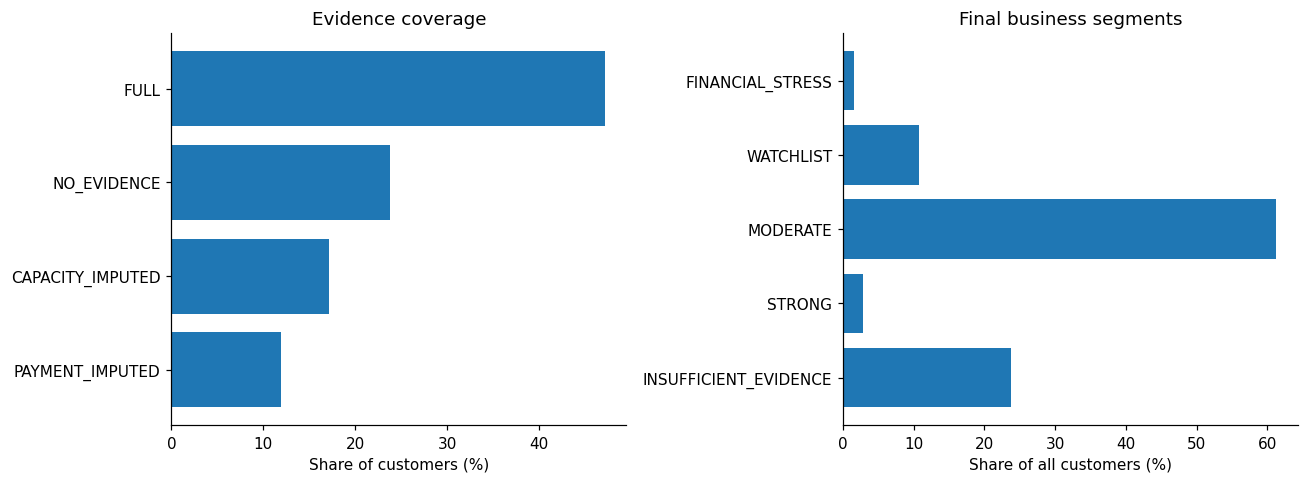

In [18]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
cov=coverage.sort_values('CUSTOMERS',ascending=False)
axes[0].barh(cov.SCORE_EVIDENCE_FLAG,cov.CUSTOMERS/len(score)*100)
axes[0].invert_yaxis();axes[0].set(xlabel='Share of customers (%)',title='Evidence coverage')
seg_counts=score.FINANCIAL_HEALTH_SEGMENT.value_counts().reindex(
    ['FINANCIAL_STRESS','WATCHLIST','MODERATE','STRONG','INSUFFICIENT_EVIDENCE']).fillna(0)
axes[1].barh(seg_counts.index,seg_counts.values/len(score)*100)
axes[1].invert_yaxis();axes[1].set(xlabel='Share of all customers (%)',title='Final business segments')
fig.tight_layout();fig.savefig(figdir/'01_coverage_and_segmentation.png',bbox_inches='tight');plt.show()

## 19 · Visualization 2: score distribution FULL vs IMPUTED

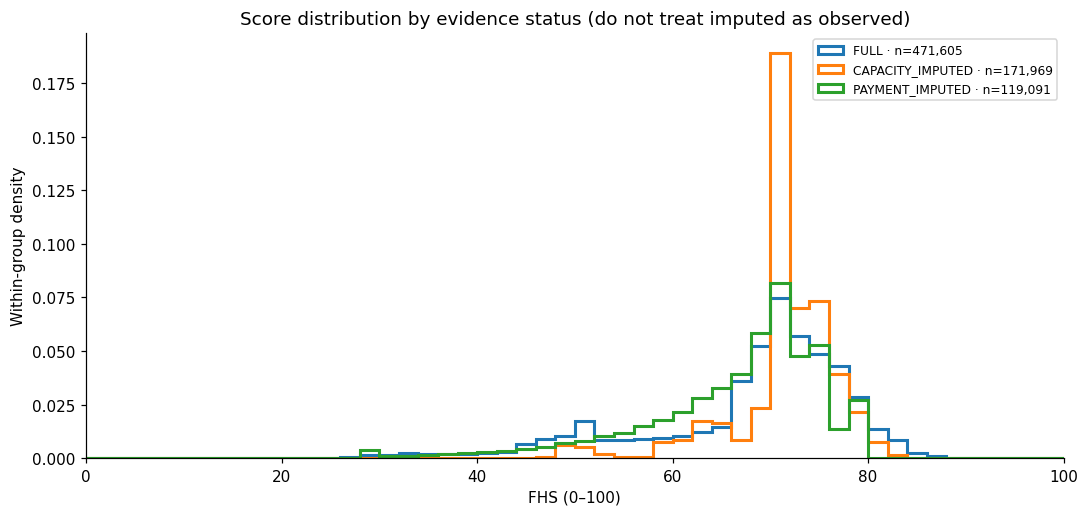

In [19]:
fig,ax=plt.subplots(figsize=(10,4.8))
for f in ['FULL','CAPACITY_IMPUTED','PAYMENT_IMPUTED']:
    z=score.loc[score.SCORE_EVIDENCE_FLAG.eq(f),'FINANCIAL_HEALTH_SCORE'].dropna()
    if not z.empty:ax.hist(z,bins=np.arange(0,102,2),density=True,histtype='step',linewidth=2,
                           label=f'{f} · n={len(z):,}')
ax.set(xlim=(0,100),xlabel='FHS (0–100)',ylabel='Within-group density',
       title='Score distribution by evidence status (do not treat imputed as observed)')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(figdir/'02_score_distributions.png',bbox_inches='tight');plt.show()

## 20 · Visualization 3: strongest observed factors & severe credit events

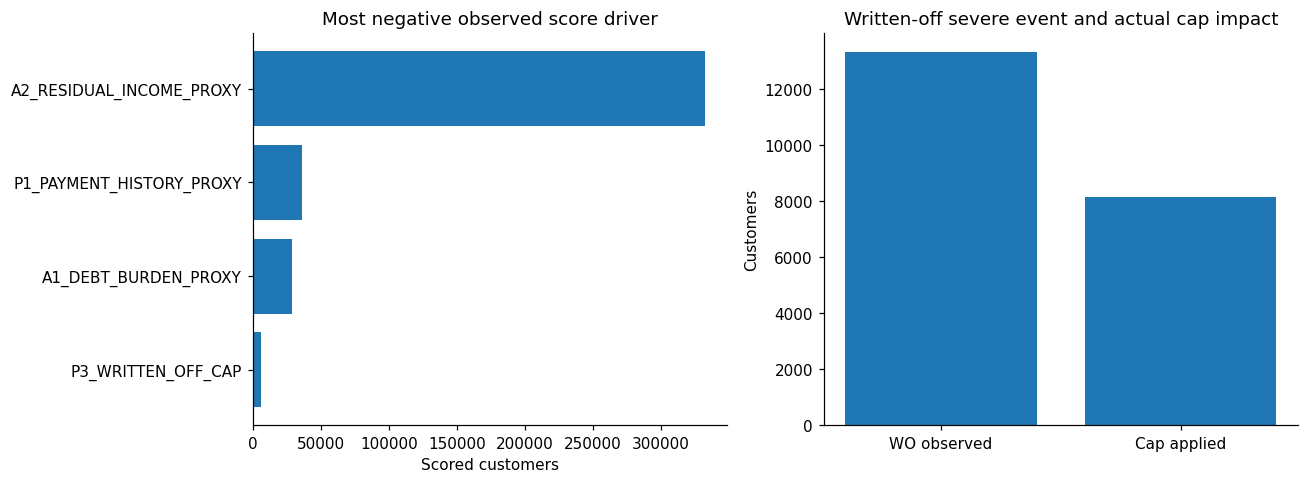

In [20]:
factor_counts=score.loc[finite,'TOP_NEGATIVE_FACTOR'].value_counts().drop('NONE',errors='ignore')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
if not factor_counts.empty: axes[0].barh(factor_counts.index[::-1],factor_counts.values[::-1])
axes[0].set(xlabel='Scored customers',title='Most negative observed score driver')
axes[1].bar(['WO observed','Cap applied'],[len(wo_audit),int(wo_audit.CAP_ACTUALLY_APPLIED.sum())])
axes[1].set(ylabel='Customers',title='Written-off severe event and actual cap impact')
fig.tight_layout();fig.savefig(figdir/'03_score_drivers_and_cap.png',bbox_inches='tight');plt.show()

## 21 · Visualization 4: historical approval overall & per product

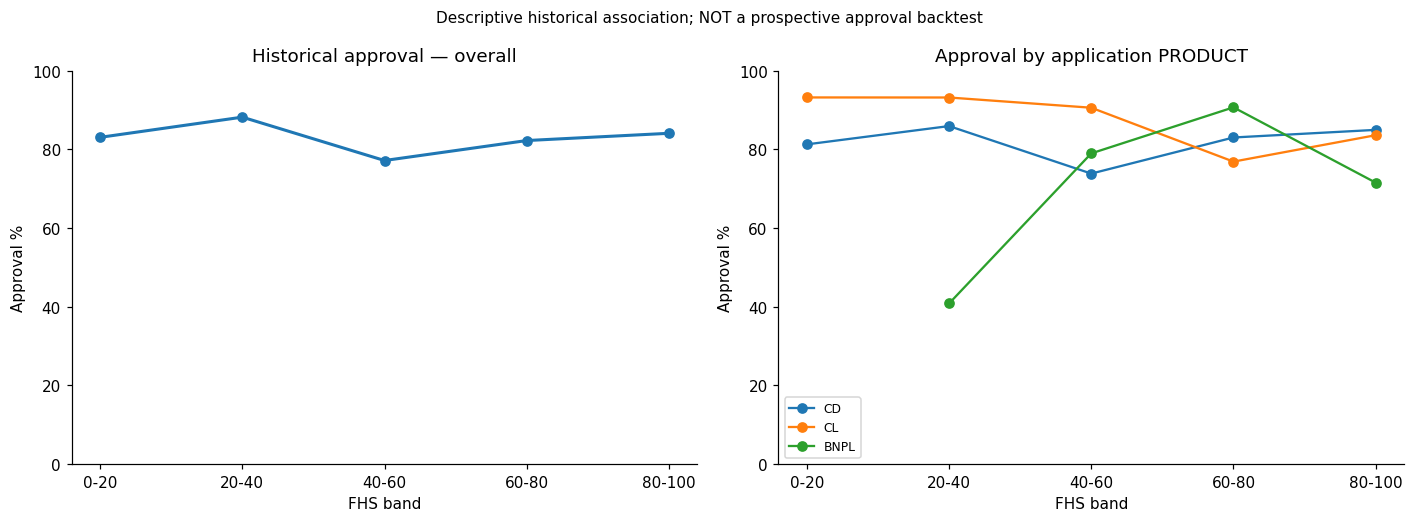

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
x=np.arange(5)
all_rates=by_band.set_index('SCORE_BAND').reindex(band_order)
axes[0].plot(x,all_rates.APPROVAL_RATE_PCT,marker='o',linewidth=2)
axes[0].set(xticks=x,xticklabels=band_order,ylim=(0,100),xlabel='FHS band',ylabel='Approval %',
    title='Historical approval — overall')
for product in product_volume.head(3).index:
    z=by_product[(by_product.PRODUCT==product)&(by_product.SUFFICIENT_SAMPLE)]
    y=z.set_index('SCORE_BAND').reindex(band_order).APPROVAL_RATE_PCT
    axes[1].plot(x,y,marker='o',label=product)
axes[1].set(xticks=x,xticklabels=band_order,ylim=(0,100),xlabel='FHS band',
           ylabel='Approval %',title='Approval by application PRODUCT')
axes[1].legend(fontsize=8)
fig.suptitle('Descriptive historical association; NOT a prospective approval backtest',fontsize=10)
fig.tight_layout();fig.savefig(figdir/'04_historical_approval_alignment.png',bbox_inches='tight');plt.show()

## 22 · Visualization 5: calibration stability (not a predictive optimum)

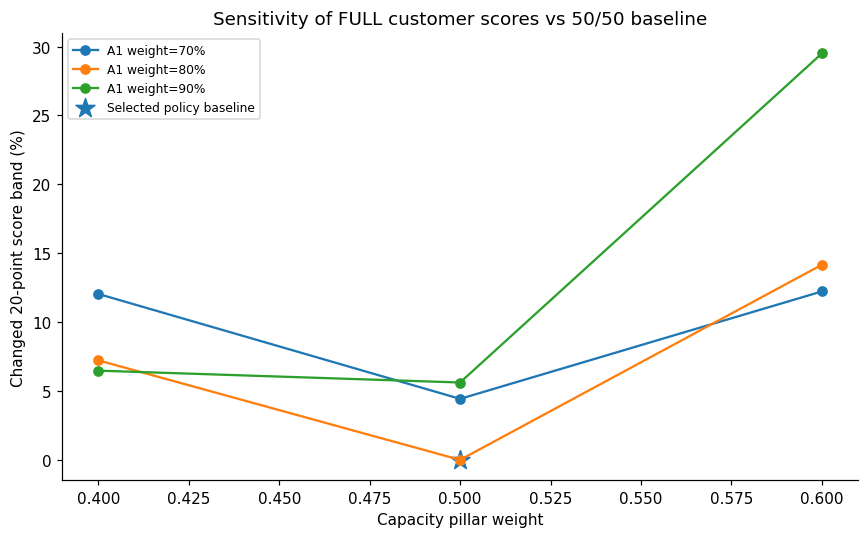

In [22]:
wplot=weight_decisions.copy()
fig,ax=plt.subplots(figsize=(8,5))
for a1_w,g in wplot.groupby('A1_WEIGHT'):
    ax.plot(g.C_WEIGHT,g.BAND_CHANGED_PCT,marker='o',label=f'A1 weight={a1_w:.0%}')
ax.scatter([wc],[0],marker='*',s=170,label='Selected policy baseline')
ax.set(xlabel='Capacity pillar weight',ylabel='Changed 20-point score band (%)',
       title='Sensitivity of FULL customer scores vs 50/50 baseline')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(figdir/'05_weight_sensitivity.png',bbox_inches='tight');plt.show()

## 23 · Final QA: no score, scoring version or reason-code inconsistencies

In [23]:
assert score.SKP_CLIENT.is_unique and len(score)==EXPECTED_CUSTOMERS
assert score.loc[~finite,'FINANCIAL_HEALTH_SEGMENT'].eq('INSUFFICIENT_EVIDENCE').all()
assert score.loc[wo&finite,'FINANCIAL_HEALTH_SCORE'].le(cap+3e-5).all()
assert score.loc[(~wo)&finite,'FINANCIAL_HEALTH_SCORE'].between(0,100).all()
assert (score.loc[flags=='FULL','IMPUTATION_SOURCE']=='OBSERVED_BOTH').all()
assert (score.loc[~finite,'TOP_POSITIVE_FACTOR']=='NONE').all()
assert (score.loc[~finite,'TOP_NEGATIVE_FACTOR']=='NONE').all()
print('ALL SIGN-OFF CHECKS PASSED:', f'{finite.sum():,} scored / {len(score):,} customers')

ALL SIGN-OFF CHECKS PASSED: 762,665 scored / 1,000,528 customers


## 24 · Export customer CSV, selected parameters, and audit tables to FIXED folder

In [24]:
business_cols=['SKP_CLIENT','CAPACITY_SCORE','PAYMENT_SCORE','FINANCIAL_HEALTH_SCORE',
 'SCORE_EVIDENCE_FLAG','FINANCIAL_HEALTH_SEGMENT','BUSINESS_ACTION_GUARDRAIL',
 'WRITTEN_OFF_OBSERVED','TOP_POSITIVE_FACTOR','TOP_NEGATIVE_FACTOR',
 'POSITIVE_EVIDENCE_CODES','NEGATIVE_EVIDENCE_CODES','DATA_WARNINGS','SCORING_VERSION']
wide_file=out/'customer_financial_health_FINAL.csv'
biz_file=out/'customer_financial_health_BUSINESS.csv'
score.drop(columns=['DATA_ENRICHMENT_FLAG'],errors='ignore').to_csv(
    wide_file,index=False,float_format='%.6f',encoding='utf-8-sig')
score[business_cols].to_csv(biz_file,index=False,float_format='%.3f',encoding='utf-8-sig')
config_final=dict(config)
config_final.update({'finalization_stage':'C1_CHALLENGE1_FINAL','selected_run':str(run),
 'customer_count':int(len(score)),'scored_customer_count':int(finite.sum()),
 'scored_pct':float(100*finite.mean()),'selection_is_predictive_optimum':False,
 'business_validation':'Historical approval association; potential temporal leakage',
 'income_period_unverified':not config.get('income_period_confirmed',False),
 'payment_maturity_unverified':not config.get('payment_maturity_confirmed',False)})
(out/'selected_scoring_config.json').write_text(json.dumps(config_final,ensure_ascii=False,indent=2),encoding='utf-8')
(out/'selected_weights.json').write_text(json.dumps({
 'capacity_weight':wc,'payment_weight':1-wc,'a1_weight_in_capacity':wa,
 'a2_weight_in_capacity':1-wa,'total_a1_weight':wc*wa,'total_a2_weight':wc*(1-wa),
 'total_p1_weight':1-wc,'written_off_cap':cap,'prior_k':config['prior_k'],
 'rationale':'Explainable policy baseline selected by stability; not predictive optimum.'
},indent=2,ensure_ascii=False),encoding='utf-8')
print('FINAL CUSTOMER CSV:',wide_file,'\nBUSINESS CSV:',biz_file,
      '\nPARAMETERS:',out/'selected_scoring_config.json')

FINAL CUSTOMER CSV: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_CHALLENGE1_FINAL\customer_financial_health_FINAL.csv 
BUSINESS CSV: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_CHALLENGE1_FINAL\customer_financial_health_BUSINESS.csv 
PARAMETERS: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_CHALLENGE1_FINAL\selected_scoring_config.json


## 25 · Save validation reports and traceable selection evidence

In [25]:
tables={
 '01_coverage.csv':coverage,'02_score_percentiles.csv':distribution,
 '03_segments_by_evidence.csv':segment_table,'04_written_off_cap_audit.csv':wo_sum,
 '05_approval_overall.csv':by_band,'06_approval_by_evidence.csv':by_evidence,
 '07_approval_by_product.csv':by_product,'08_approval_by_cohort.csv':by_cohort,
 '09_approval_product_cohort_evidence.csv':by_product_cohort,
 '10_contract_decision_status_audit.csv':status,
 '11_selected_weight_decision.csv':weight_decisions,
 '12_corrected_masked_validation.csv':masked_checks,
 '13_imputation_method_selection.csv':impute_decisions,
 '14_stress_parameter_tests.csv':stress_checks}
reportdir=out/'validation_tables';reportdir.mkdir(exist_ok=True)
for name,frame in tables.items():frame.to_csv(reportdir/name,index=False,encoding='utf-8-sig')
reason_counts=pd.concat([
    score.TOP_POSITIVE_FACTOR.value_counts().rename_axis('DRIVER').reset_index(name='CUSTOMERS').assign(TYPE='TOP_POSITIVE'),
    score.TOP_NEGATIVE_FACTOR.value_counts().rename_axis('DRIVER').reset_index(name='CUSTOMERS').assign(TYPE='TOP_NEGATIVE')
],ignore_index=True)
reason_counts.to_csv(reportdir/'15_top_factor_summary.csv',index=False,encoding='utf-8-sig')
print('AUDIT TABLES:',len(tables)+1,'| FIGURES:',len(list(figdir.glob('*.png'))))

AUDIT TABLES: 15 | FIGURES: 5


## 26 · Manifest + final file verification (including customer counts)

In [26]:
check_wide=pd.read_csv(wide_file,usecols=['SKP_CLIENT','FINANCIAL_HEALTH_SCORE','SCORE_EVIDENCE_FLAG'],
    dtype={'SKP_CLIENT':'string'})
check_biz=pd.read_csv(biz_file,usecols=['SKP_CLIENT','FINANCIAL_HEALTH_SCORE'],
    dtype={'SKP_CLIENT':'string'})
for label,data in [('WIDE',check_wide),('BUSINESS',check_biz)]:
    assert len(data)==EXPECTED_CUSTOMERS and data.SKP_CLIENT.is_unique
    assert data.FINANCIAL_HEALTH_SCORE.notna().sum()==finite.sum()
assert set(check_wide.SKP_CLIENT)==set(check_biz.SKP_CLIENT)
manifest={'source_run':str(run),'generated_utc':datetime.now(timezone.utc).isoformat(),
    'n_customers':EXPECTED_CUSTOMERS,'n_scored':int(finite.sum()),
    'n_not_scored':int((~finite).sum()),'scoring_version':config['scoring_version'],
    'selected_config':'selected_scoring_config.json',
    'files':[{'relative_path':str(p.relative_to(out)), 'bytes':p.stat().st_size}
             for p in sorted(out.rglob('*')) if p.is_file() and p.name!='manifest.json']}
(out/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('VERIFIED: all',f'{EXPECTED_CUSTOMERS:,}','customers in BOTH CSV exports.')
print('FINAL FOLDER:',out)
print('FILES:',len(manifest['files']))

VERIFIED: all 1,000,528 customers in BOTH CSV exports.
FINAL FOLDER: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_CHALLENGE1_FINAL
FILES: 24


## Notes for competition documentation (do not claim unproven validity)

- **A1/A2** rely on an income-period assumption and incomplete internal debt-service obligations. Score is financial-health *proxy*, not verified DTI or disposable income.
- **P1** uses overdue flags and proxy observable cases. A no-DUE observation is not proven future non-default; the empirical-Bayes prior controls sparse samples.
- **P3** is an explicit severe-event override. Record cap effects, including customers already below cap.
- **Imputation** is evaluated by masked validation, but that cannot eliminate Missing Not At Random risk; distinguish FULL vs IMPUTED.
- **Weights 50/50 and 80/20** were selected as an interpretable, stable policy baseline (not a predictive optimum). `prior_k` was estimated from observed case-DUE count variability.
- **Approval Rate** uses case-level historical final decisions including events that may post-date approval. Never present it as out-of-time predictive validation; repeated customers mean case-level Wilson intervals are descriptive.
- **FHS segments** are heuristic action groups, not regulatory credit risk classes; use `BUSINESS_ACTION_GUARDRAIL` and evidence status before next-best-action decisions.
